In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from config.paths import EXTRACTED_ROOT, LABELS_ROOT
from scipy.spatial.transform import Rotation as R

CONF_THRESH = 0.6  # min RHE confidence to trust a mu/nu label
LOW_THRESH = 0.75  # mu/nu at or below this counts as low traversability

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)


excluded_missions = {"ICE-1"}  # ICE-1 has unreliable RHE labels


def mission_stats(d: Path, rhe_dir: Path) -> dict | None:
    """Per-mission summary row, or None if core labels are missing."""
    trav = np.load(rhe_dir / "rhe_trav_labels.npy")
    ts = np.load(rhe_dir / "rhe_timestamp.npy").astype(float)
    mu, nu = trav[:, 0], trav[:, 1]

    mu_c = np.load(rhe_dir / "rhe_mu_observability.npy")
    nu_c = np.load(rhe_dir / "rhe_nu_observability.npy")
    conf_mu, conf_nu = mu_c >= CONF_THRESH, nu_c >= CONF_THRESH

    v = np.full(len(ts), np.nan)
    odom = np.load(d / "dlio_odom.npy")
    t_odom = odom[:, 0].astype(float)
    x = odom[:, 1]
    y = odom[:, 2]
    yaw = R.from_quat(odom[:, 4:8]).as_euler("zyx")[:, 0]
    vx, vy = np.gradient(x, t_odom), np.gradient(y, t_odom)
    v_odom = vx * np.cos(yaw) + vy * np.sin(yaw)
    v = np.interp(ts, t_odom, v_odom, left=np.nan, right=np.nan)

    return {
        "env": d.name.split("-")[0],
        "N": len(mu),
        "img": (d / "image_manifest.npz").exists(),
        "depth": (d / "depth_manifest.npz").exists(),
        "dur_min": (ts[-1] - ts[0]) / 60,
        "v_med": float(np.nanmedian(np.abs(v))),
        "stop_pct": 100 * float(np.mean(np.abs(v) < 0.1)),
        "muC_pct": 100 * float(conf_mu.mean()),
        "nuC_pct": 100 * float(conf_nu.mean()),
        "low_mu": int(((mu <= LOW_THRESH) & conf_mu).sum()),
        "low_nu": int(((nu <= LOW_THRESH) & conf_nu).sum()),
        "mu_med": float(np.median(mu)),
        "nu_med": float(np.median(nu)),
    }


def _stats_or_none(d: Path) -> dict | None:
    rhe_dir = LABELS_ROOT / d.name / "rhe"
    if not (rhe_dir / "rhe_trav_labels.npy").exists():
        return None
    return mission_stats(d, rhe_dir)


rows = {
    d.name: _stats_or_none(d)
    for d in sorted(EXTRACTED_ROOT.iterdir())
    if d.is_dir() and d.name not in excluded_missions
}
rows = {m: s for m, s in rows.items() if s is not None}

df = pd.DataFrame.from_dict(rows, orient="index")
df = df.sort_values(["env"], ascending=[True])
df.index.name = "mission"


print(f"{len(df)} missions")
print(
    f"CONF_THRESH: conf >= {CONF_THRESH},  LOW_THRESH: traversability <= {LOW_THRESH}"
)
print(
    f"totals: confident-low mu={df.low_mu.sum()} ({df.low_mu.sum() / df.N.sum() * 100:.1f}%), confident-low nu={df.low_nu.sum()} ({df.low_nu.sum() / df.N.sum() * 100:.1f}%)"
)
print(f"missions with images={int(df.img.sum())}")
df.round(2)

48 missions
CONF_THRESH: conf >= 0.6,  LOW_THRESH: traversability <= 0.75
totals: confident-low mu=13180 (7.5%), confident-low nu=8422 (4.8%)
missions with images=48


,env,N,img,depth,dur_min,v_med,stop_pct,muC_pct,nuC_pct,low_mu,low_nu,mu_med,nu_med
mission,,,,,,,,,,,,,
ALB-1,ALB,2405,True,True,4.01,0.44,17.26,86.61,44.53,352,144,0.83,0.83
ALB-2,ALB,4599,True,True,7.66,0.38,21.94,85.04,31.57,1546,698,0.81,0.80
ALB-3,ALB,1739,True,True,2.90,0.39,13.23,91.49,43.47,440,144,0.80,0.81
ARC-1,ARC,4009,True,True,6.68,0.61,11.80,92.14,46.77,428,78,0.91,0.91
ARC-2,ARC,3620,True,True,6.03,0.31,31.08,78.23,55.58,646,260,0.86,0.88
ARC-3,ARC,6340,True,True,10.56,0.41,21.62,85.71,55.90,926,496,0.89,0.87
ARC-4,ARC,3538,True,True,5.89,0.39,24.22,81.97,46.01,254,166,0.88,0.87
ARC-5,ARC,2770,True,True,4.61,0.62,10.47,91.26,44.77,76,72,0.91,0.92
ARC-6,ARC,2763,True,True,4.60,0.41,27.33,74.81,34.13,64,0,0.88,0.89


Choosing the train / held-out (ID) and OOD split for the GrandTour traversability data.

The split has **two orthogonal axes**:
1. **ID-internal** (train / held-out) - split by whole RUN *within the same families*. Terrain repeats on purpose: the held-out ID set has to be unambiguously in-distribution, since it is the negative class of the OOD-detection benchmark. Train and val are merged into one train set; the held-out ID set doubles as the checkpoint-monitor (val) and the OOD negative class.
2. **ID vs OOD** - **ID = forest only** (natural off-road); keeping the ID narrow is what makes the built and snow environments genuinely far rather than overlapping a broad ID. Held out as OOD, in a graded near->far spectrum:
   - **near-OOD, forest tier**: KAEB-1 (entangling undergrowth) + ROOT-1 (large roots/boulders), two subtle same-biome shifts (vegetation, geometry).
   - **near-OOD, gravel tier**: EIG-1/2 + PIL-2, alpine/mountain runs whose *surface* (gravel) is shared with ID forest trails, so they are near on surface but the scene is displaced.
   - **far-OOD**: SNOW (natural/surface extreme) + ARC-1..4 (built/industrial extreme, day runs).

   **KAEB straddles on purpose**: KAEB-2/3 sit in ID (normal Kaeferberg forest), KAEB-1 is near-OOD (same forest plus the entanglement hazard). The split is run-level disjoint, so this is the only allowed ID/OOD family overlap. Sensor-dropout is the depth-off pass over the held-out ID rows, not a separate family.

Coverage to keep: confident-low mu/nu must exist in ID-train and the held-out ID set (low-trav is otherwise untestable); low-mu is *not* required in OOD (there it only feeds the separate failure-mode analysis).

Rationale documented in `documentation/ood_split.md`; property-space reasoning in `documentation/environment_properties.md`. Cell 1 prints the per-mission table; use the env rollup and `evaluate_split` to test candidates.

### Environment rollup

In [2]:
# Environment-level rollup: a terrain-aware split must not let one env straddle train/valid.
env = (
    df
    .groupby("env")
    .agg(
        missions=("N", "size"),
        with_img=("img", "sum"),
        N=("N", "sum"),
        low_mu=("low_mu", "sum"),
        low_nu=("low_nu", "sum"),
        dur_min=("dur_min", "sum"),
    )
    .sort_values("low_mu", ascending=False)
)
env.round(1)

,missions,with_img,N,low_mu,low_nu,dur_min
env,,,,,,
ARC,7,7,26013,2612,1096,43.3
ALB,3,3,8743,2338,986,14.6
KAEB,3,3,11645,1322,1086,19.4
LMB,2,2,6560,1112,1120,10.9
EIG,2,2,7121,928,448,11.9
CON,4,4,18627,838,328,31.0
PIL,2,2,13532,724,496,22.5
RIV,1,1,4708,696,230,7.8
SNOW,3,3,5622,462,166,9.4


### Evaluate a candidate split

In [ ]:
# --- Final OOD-detection split (see documentation/ood_split.md) ---
# ID = forest only (natural off-road), split by RUN within family (terrain repeats on purpose,
# so the held-out ID set is unambiguously the negative class). A forest-only ID keeps the
# built/snow environments genuinely far instead of overlapping a broad ID.
# train+val merged into one set; the held-out ID set doubles as checkpoint monitor (val) and OOD negative class.
# KAEB straddles ON PURPOSE: KAEB-2/3 in ID (normal Kaeferberg forest), KAEB-1 near-OOD
# (same forest + entanglement hazard). Run-level disjoint, so no leak.
SPLIT = {
    "train":   ["ALB-1", "ALB-2", "CYN-1", "HOEB-1", "LMB-1", "RIV-1", "TRIM-1", "HIL-1", "KAEB-2", "KAEB-3"],
    "heldout": ["ALB-3", "LMB-2", "HOEB-2", "CYN-2"],  # valid == test
}

OOD = {
    "near_forest": ["KAEB-1", "ROOT-1"],              # forest: vegetation + geometry shift
    "near_gravel": ["EIG-1", "EIG-2", "PIL-2"],       # alpine/mountain, gravel surface shared with ID forest trails
    "far_snow":    ["SNOW-1", "SNOW-2", "SNOW-3"],    # natural/surface extreme
    "far_arc":     ["ARC-1", "ARC-2", "ARC-3", "ARC-4"],  # built/industrial extreme (day runs)
}
ALLOWED_STRADDLE = {"KAEB"}  # intentional ID/near-OOD family straddle (run-level disjoint)

# sensor-dropout OOD = depth-off pass over the held-out ID runs (not a separate family).


def evaluate_split(id_splits: dict, ood: dict | None = None, allowed_straddle: set | None = None) -> pd.DataFrame:
    """Summarise an ID split (+ OOD groups); flag run leaks, unexpected ID/OOD env straddle, low-trav gaps."""
    ood = ood or {}
    allowed_straddle = allowed_straddle or set()

    def agg(ms):
        sub = df.loc[[m for m in ms if m in df.index]]
        return {"missions": len(sub), "N": int(sub.N.sum()), "low_mu": int(sub.low_mu.sum()),
                "low_nu": int(sub.low_nu.sum()), "n_envs": sub.env.nunique()}

    out = pd.DataFrame({k: agg(v) for k, v in {**id_splits, **ood}.items()}).T

    # every run must appear in at most one set (ID or OOD)
    seen = {}
    for name, ms in {**id_splits, **ood}.items():
        for m in ms:
            if m in seen:
                print(f"RUN-LEAK: {m} in both {seen[m]} and {name}")
            seen[m] = name

    envs = lambda ms: {df.loc[m, "env"] for m in ms if m in df.index}
    id_envs = envs([m for ms in id_splits.values() for m in ms])
    for e in id_envs - envs(id_splits["train"]):
        print(f"WARNING: env {e} absent from train (would act as OOD)")
    straddle = envs([m for ms in ood.values() for m in ms]) & id_envs
    print(f"family straddle ID/OOD: {straddle or 'none'} (allowed: {allowed_straddle or 'none'})")
    if straddle - allowed_straddle:
        print(f"UNEXPECTED straddle: {straddle - allowed_straddle}")
    for name in id_splits:
        if out.loc[name, "low_mu"] == 0:
            print(f"WARNING: {name} has no confident-low MU")
    return out


evaluate_split(SPLIT, OOD, ALLOWED_STRADDLE)

### Reading the table

- `low_mu` / `low_nu`: confident-low samples (`mu`/`nu` <= `LOW_THRESH` and confidence >= `CONF_THRESH`) - the scarce, safety-critical class.
- `muC_pct` / `nuC_pct`: fraction of timesteps with trustworthy mu / nu. Expect `nuC_pct` to be low (the robot rarely turns, so angular traversability is under-observed).
- `img`: trainable. All missions now have images.

### Picking a split

`evaluate_split(id_splits, ood)` takes the ID splits as a dict (`train`/`heldout`) plus the OOD groups. It flags: a run appearing in two ID splits, an ID family missing from `train` (it would act as OOD), an OOD family leaking into ID, and any ID split with zero confident-low mu. Within the same family, runs *should* repeat across ID splits - that is the point; only the OOD families stay fully held out.

The final `SPLIT` merges train and val; the single `heldout` ID set is the checkpoint-monitor signal, the RQ1 in-domain test, and the OOD negative class (reused depth-off for the sensor-dropout case). Coupling checkpoint selection to the held-out set touches only the RQ1 number; AUROC/FPR95 are computed post-hoc and unaffected, and the architecture is fixed so no HP-search bias compounds.

### High-confidence mu/nu over time, per mission

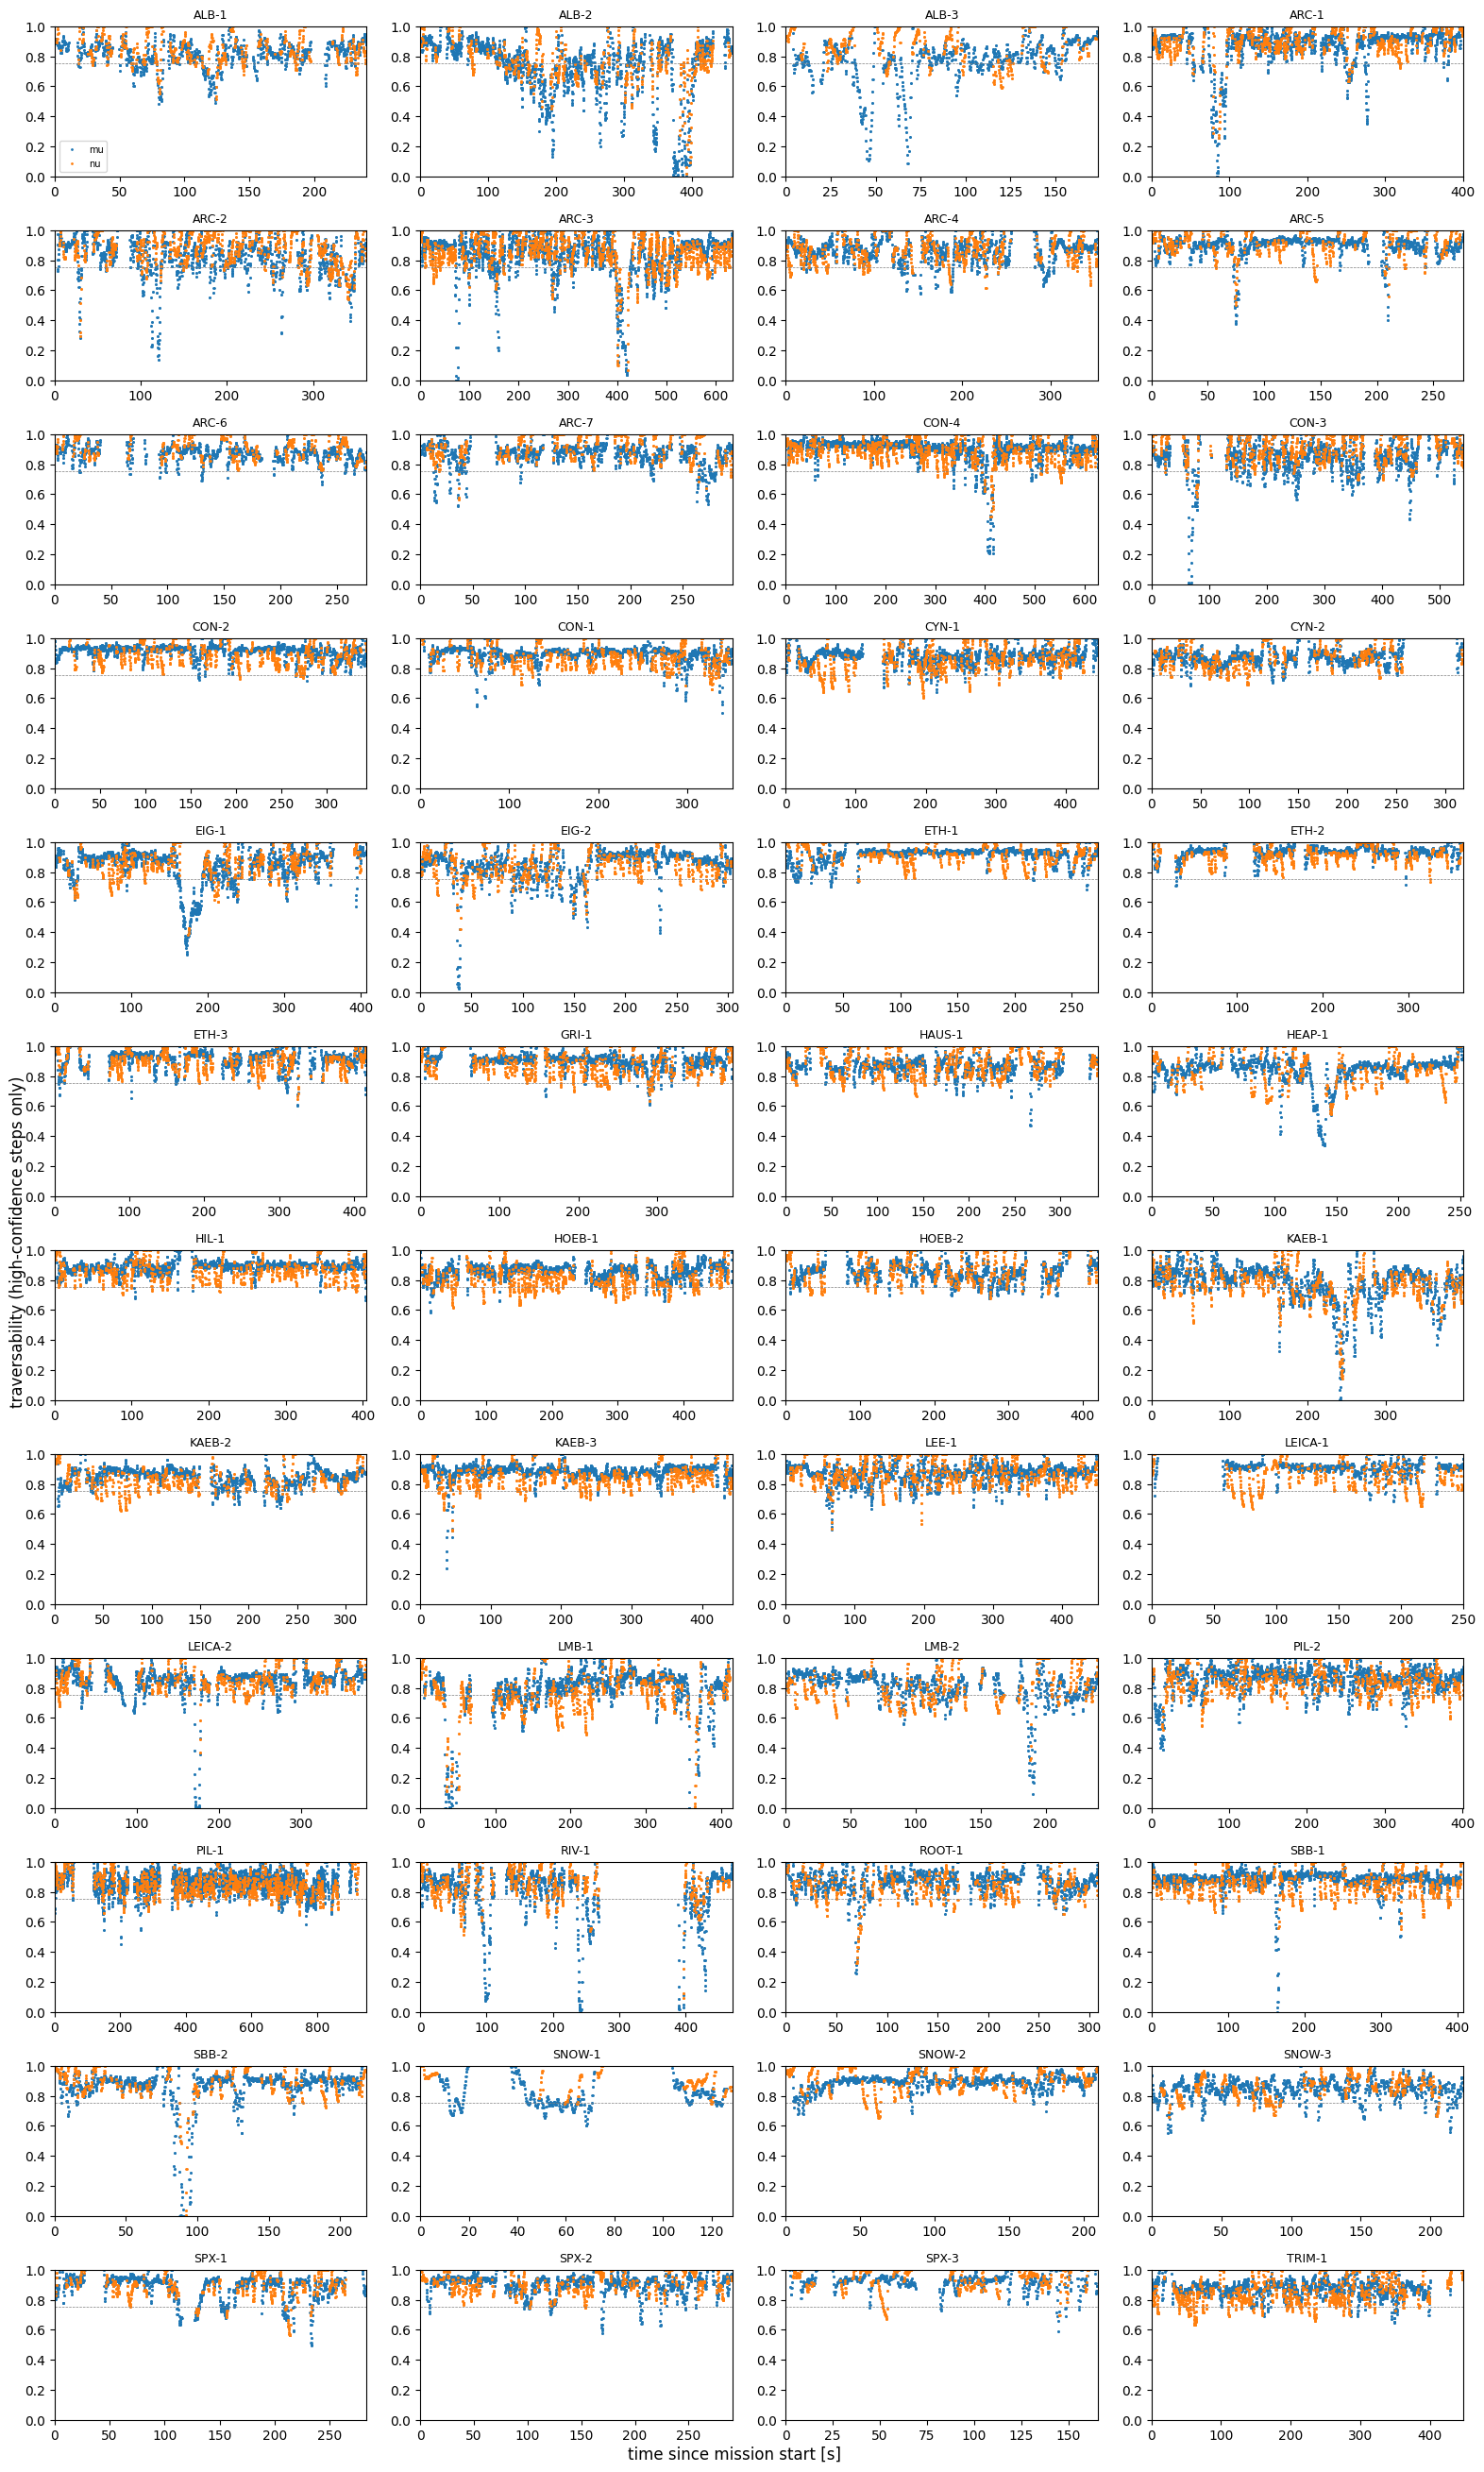

In [4]:
import matplotlib.pyplot as plt

# Per-mission mu/nu over time, masked to high-confidence steps only.
# Low-confidence steps are left blank; the x axis still spans the full mission.
missions = df.index.tolist()
ncols = 4
nrows = -(-len(missions) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows), squeeze=False)

for ax, m in zip(axes.flat, missions):
    d = LABELS_ROOT / m / "rhe"
    trav = np.load(d / "rhe_trav_labels.npy")
    t = np.load(d / "rhe_timestamp.npy").astype(float)
    t = t - t[0]
    mu_c = np.load(d / "rhe_mu_observability.npy")
    nu_c = np.load(d / "rhe_nu_observability.npy")

    mu = np.where(mu_c >= CONF_THRESH, trav[:, 0], np.nan)
    nu = np.where(nu_c >= CONF_THRESH, trav[:, 1], np.nan)
    ax.plot(t, mu, ".", ms=2, label="mu")
    ax.plot(t, nu, ".", ms=2, label="nu")
    ax.axhline(LOW_THRESH, color="grey", lw=0.5, ls="--")
    ax.set_xlim(0, t[-1])
    ax.set_ylim(0, 1)
    ax.set_title(m, fontsize=9)

for ax in axes.flat[len(missions) :]:
    ax.axis("off")
axes.flat[0].legend(loc="lower left", fontsize=7)
fig.supxlabel("time since mission start [s]")
fig.supylabel("traversability (high-confidence steps only)")
fig.tight_layout()
plt.show()